# Visualize climate context

Load the saved ERA5-Land climate outputs and create descriptive figures: regional maps across the study region, site figures with Wadi Gaza first, and a cell-choice sensitivity check for Wadi Gaza. This notebook does not recompute summaries; run `21_compute_climate_summaries.ipynb` first. Figures are saved under `outputs/climate/plots/`. For the method, see the [ERA5-Land Climate Context white paper](../docs/white-papers/ERA5-Land-Climate-Context.md).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from cds_pull import ClimateConfig, load_sites
from cds_pull.plotting import (
    plot_cell_values,
    plot_cells_map,
    plot_climatology,
    plot_cumulative_seasons,
    plot_summary_heatmap,
    plot_temperature_anomalies,
    plot_temperature_method_difference,
    plot_wet_season_heatmap,
    save_figure,
)

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"

## Load saved outputs

In [2]:
config = ClimateConfig.from_yaml(ROOT / "configs" / "climate.yaml", project_root=ROOT)
OUT = config.output_dir
PLOT_DIR = OUT / "plots"
FOCUS_SITE = "WadiGaza"

site_cells = pd.read_csv(OUT / "site_cells.csv", keep_default_na=False)
daily = pd.read_csv(OUT / "daily_climate.csv")
normals = pd.read_csv(OUT / "climate_normals.csv")
summary = pd.read_csv(OUT / "monthly_climate_summary.csv")
regional = pd.read_csv(OUT / "regional_climate_summary.csv")
cells = gpd.read_file(OUT / "era5land_cells.gpkg")
sites = load_sites(config.sites_source, config.id_field)
SITE_ORDER = [FOCUS_SITE] + sorted(set(summary["site"]) - {FOCUS_SITE})
FOCUS_CELL = site_cells.set_index("site").loc[FOCUS_SITE, "cell_id"]
print(f"{len(summary)} site rows; {len(regional)} regional rows; {FOCUS_SITE} uses cell {FOCUS_CELL}")

196 site rows; 1008 regional rows; WadiGaza uses cell N31.5_E34.4


## Sites over the ERA5-Land grid

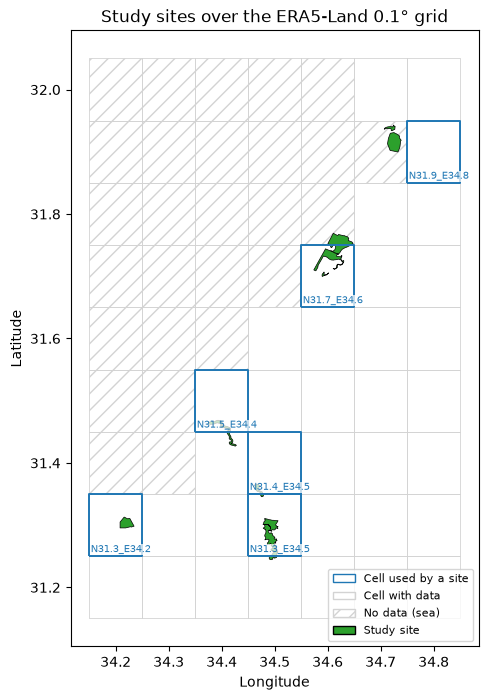

In [3]:
fig, ax = plot_cells_map(sites, cells)
save_figure(fig, PLOT_DIR / "sites_over_cells.png")
plt.show()

## Regional climatology

ERA5-Land 1991–2020 normals for every cell with data: annual precipitation (sum of the monthly normals) and annual mean temperature (mean of the monthly 24-hour-mean normals). Site outlines are shown in black.

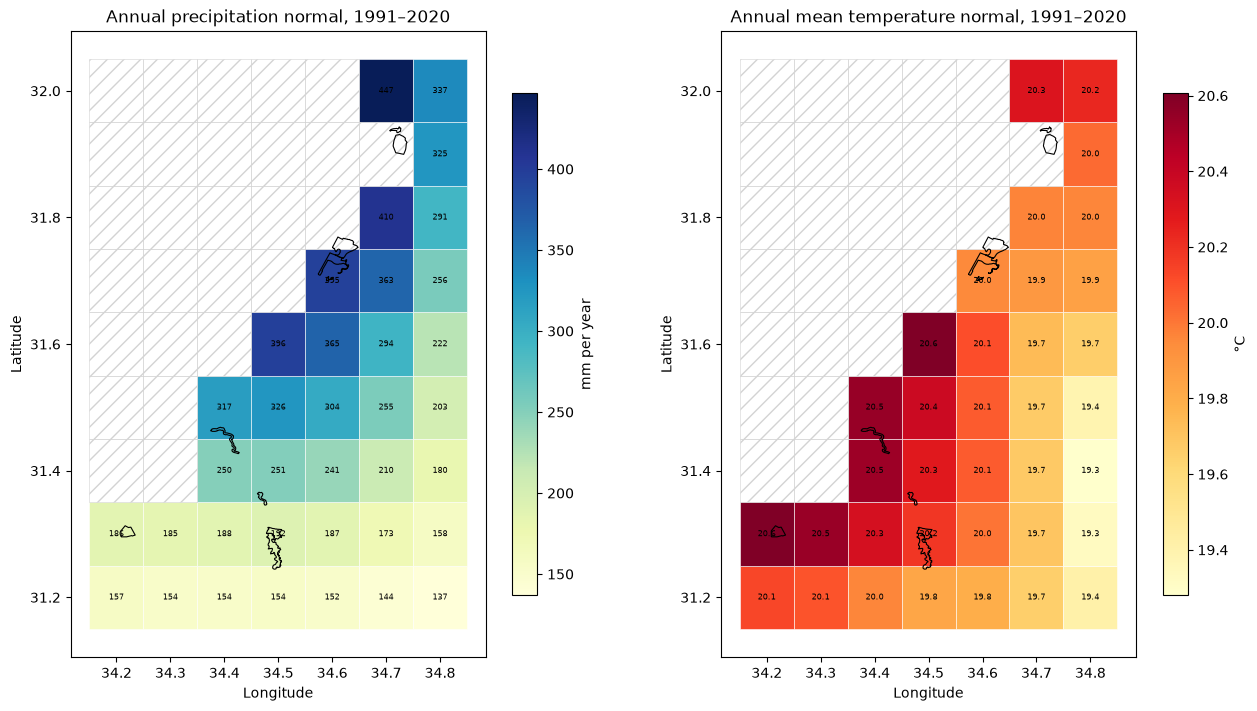

In [4]:
annual_precip = normals.loc[normals["measure"] == "precip_mm"].groupby("cell_id")["mean"].sum()
annual_temp = normals.loc[normals["measure"] == "t2m_mean_24h_c"].groupby("cell_id")["mean"].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 7), constrained_layout=True)
plot_cell_values(cells, annual_precip, sites, ax=axes[0], label="mm per year", cmap="YlGnBu")
axes[0].set_title("Annual precipitation normal, 1991\N{EN DASH}2020")
plot_cell_values(cells, annual_temp, sites, ax=axes[1], label="\N{DEGREE SIGN}C", cmap="YlOrRd", fmt="{:.1f}")
axes[1].set_title("Annual mean temperature normal, 1991\N{EN DASH}2020")
save_figure(fig, PLOT_DIR / "regional_normals.png")
plt.show()

## Regional wet-season precipitation

Percent of the 1991–2020 normal for each October–April season from 2017/18 to 2024/25, on a shared colour scale centred on 100%.

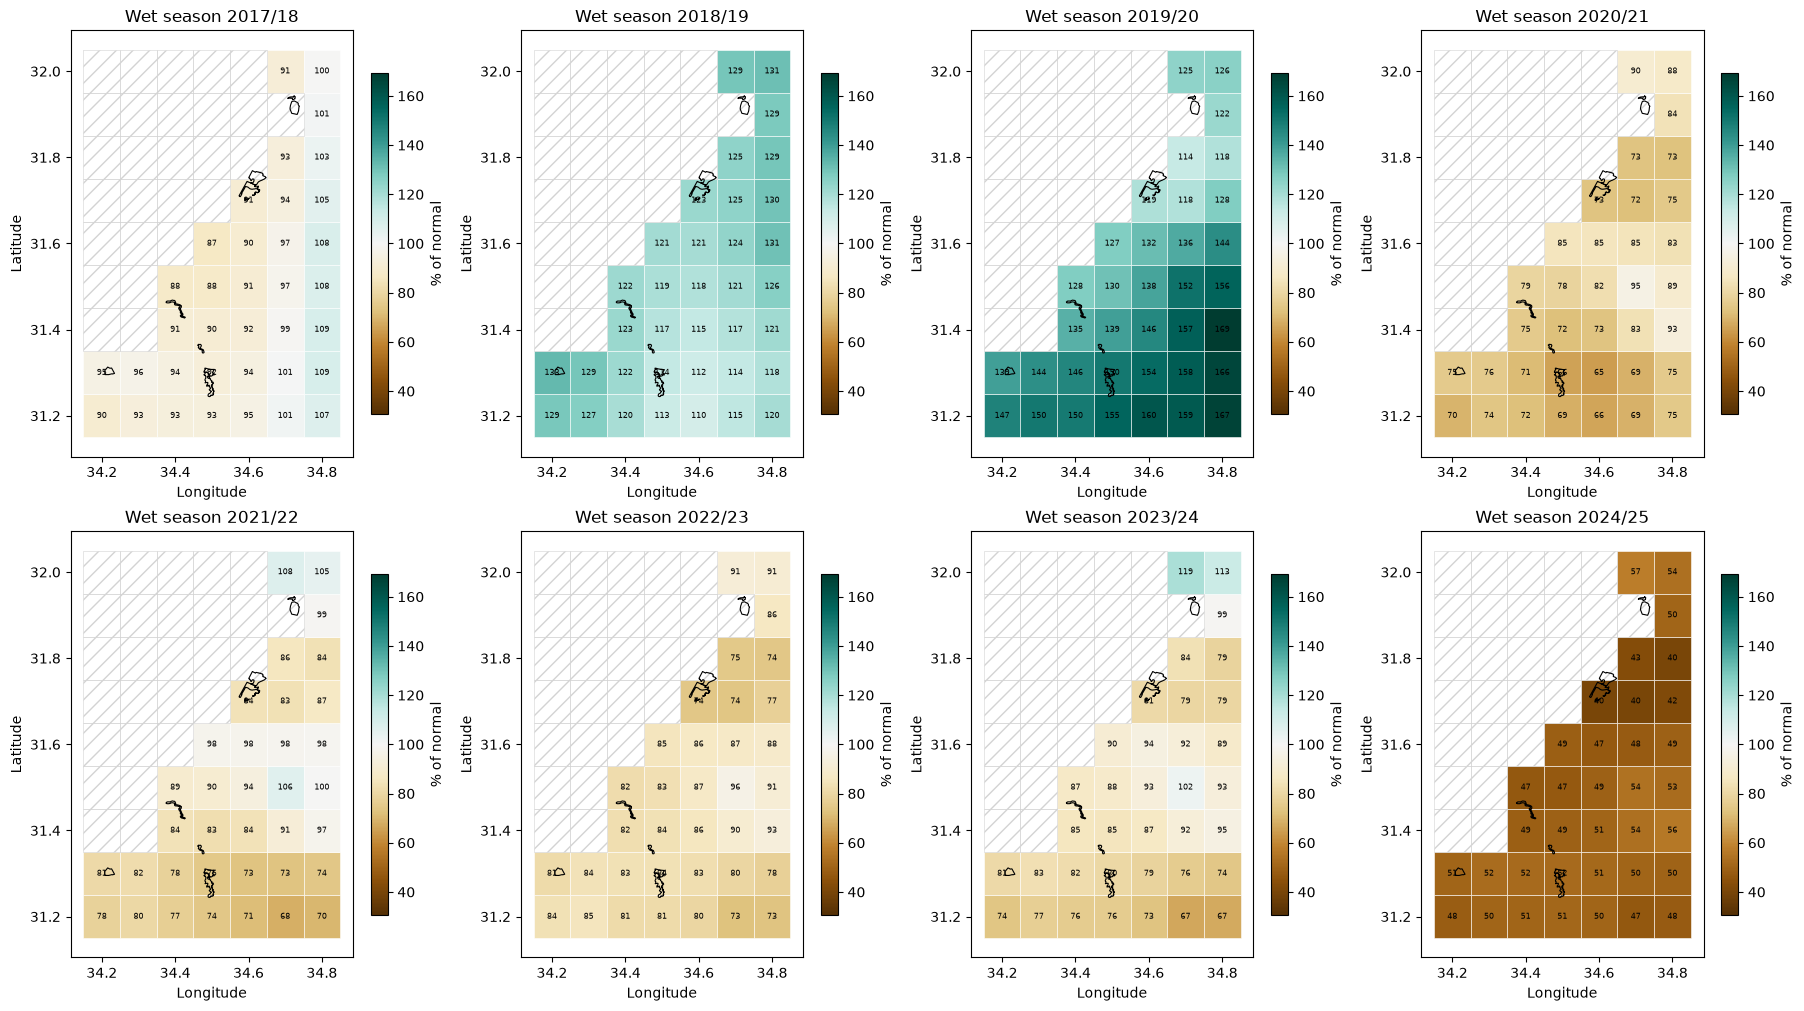

In [5]:
seasons = regional.drop_duplicates(["cell_id", "wet_season_label"])
labels = sorted(seasons["wet_season_label"].unique())
spread = (seasons["wet_season_precip_pct_normal"] - 100).abs().max()
fig, axes = plt.subplots(2, 4, figsize=(18, 10), constrained_layout=True)
for ax, label in zip(axes.flat, labels):
    values = seasons.loc[seasons["wet_season_label"] == label].set_index("cell_id")["wet_season_precip_pct_normal"]
    plot_cell_values(cells, values, sites, ax=ax, label="% of normal", cmap="BrBG", centre=100,
                     limits=(100 - spread, 100 + spread))
    ax.set_title(f"Wet season {label}")
save_figure(fig, PLOT_DIR / "regional_wet_season_pct_normal.png")
plt.show()

## Regional temperature anomaly

Mean 24-hour temperature anomaly across all 28 study months (2019–2025, January, May, September and November).

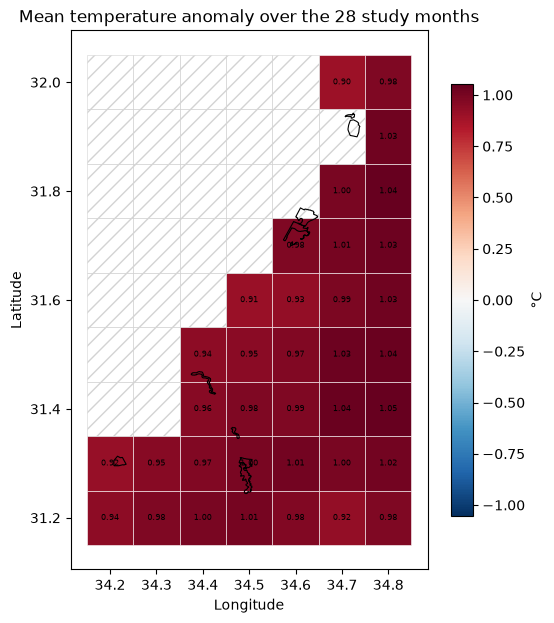

In [6]:
mean_anomaly = regional.groupby("cell_id")["t2m_mean_24h_anom_c"].mean()
fig, ax = plot_cell_values(cells, mean_anomaly, sites, label="\N{DEGREE SIGN}C", cmap="RdBu_r", centre=0,
                           fmt="{:.2f}")
ax.set_title("Mean temperature anomaly over the 28 study months")
save_figure(fig, PLOT_DIR / "regional_temperature_anomaly.png")
plt.show()

## Monthly precipitation anomaly by site

Observed minus normal (mm) for each study month. Hatched cells have a normal below the near-zero threshold, so their percent of normal is left blank.

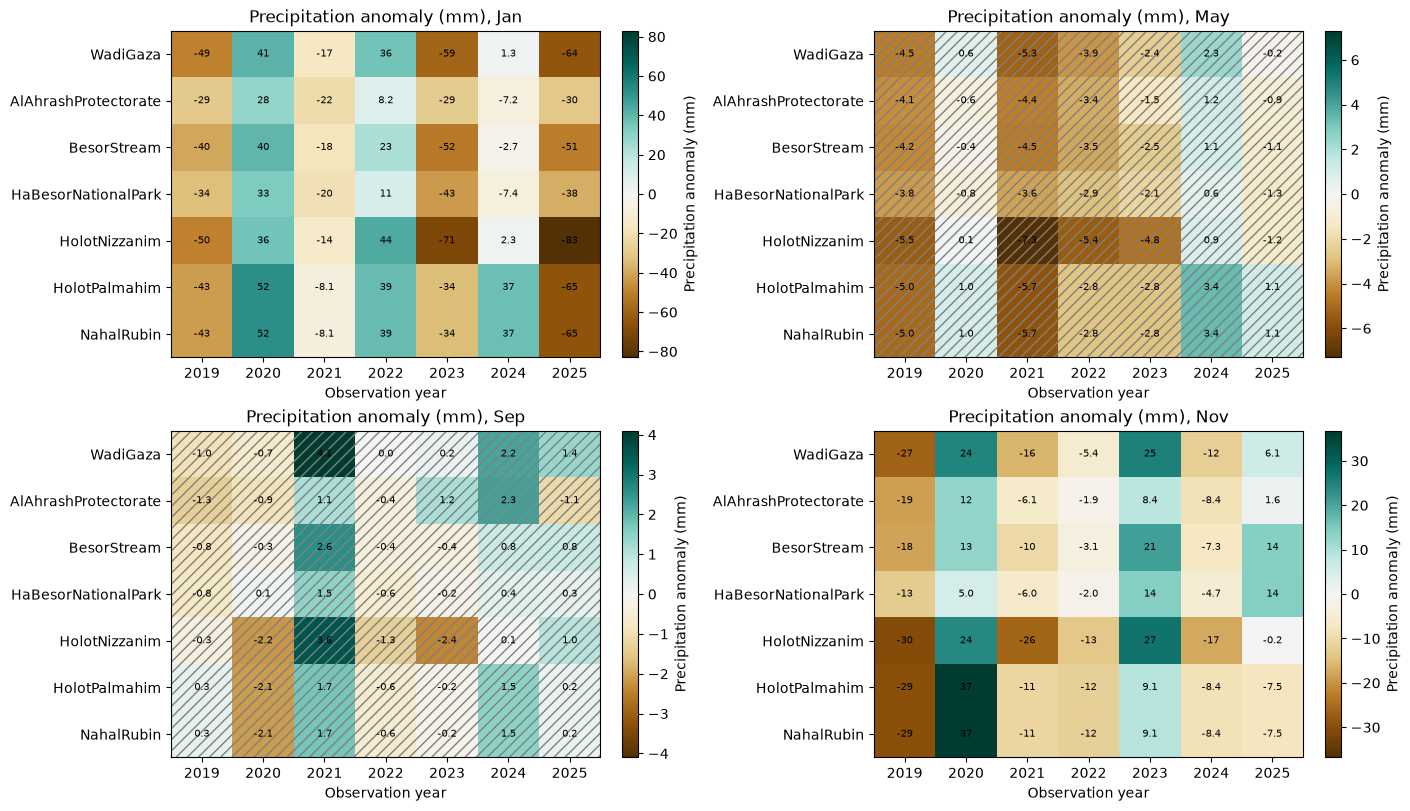

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for ax, month in zip(axes.flat, config.study_months):
    plot_summary_heatmap(summary, "precip_anom_mm", month, ax=ax, flag="precip_near_zero_normal",
                         label="Precipitation anomaly (mm)", sites=SITE_ORDER)
save_figure(fig, PLOT_DIR / "precip_anomaly_heatmaps.png")
plt.show()

## Wet-season and cumulative precipitation by site

Wet-season totals are shown once per season. Cumulative precipitation since October 1 runs to the end of the month before each observation month. For May it equals the wet-season total.

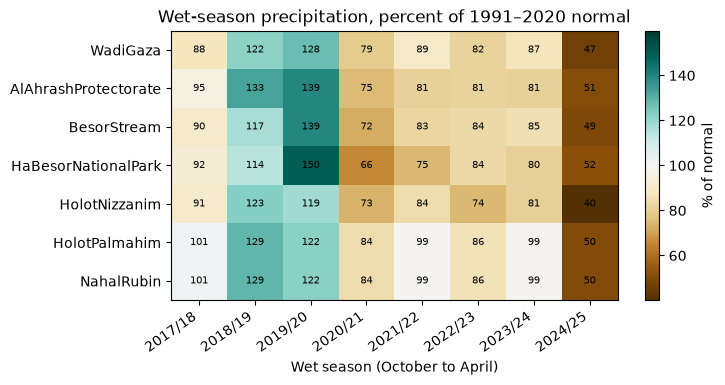

In [8]:
fig, ax = plot_wet_season_heatmap(summary, sites=SITE_ORDER)
save_figure(fig, PLOT_DIR / "wet_season_pct_normal.png")
plt.show()

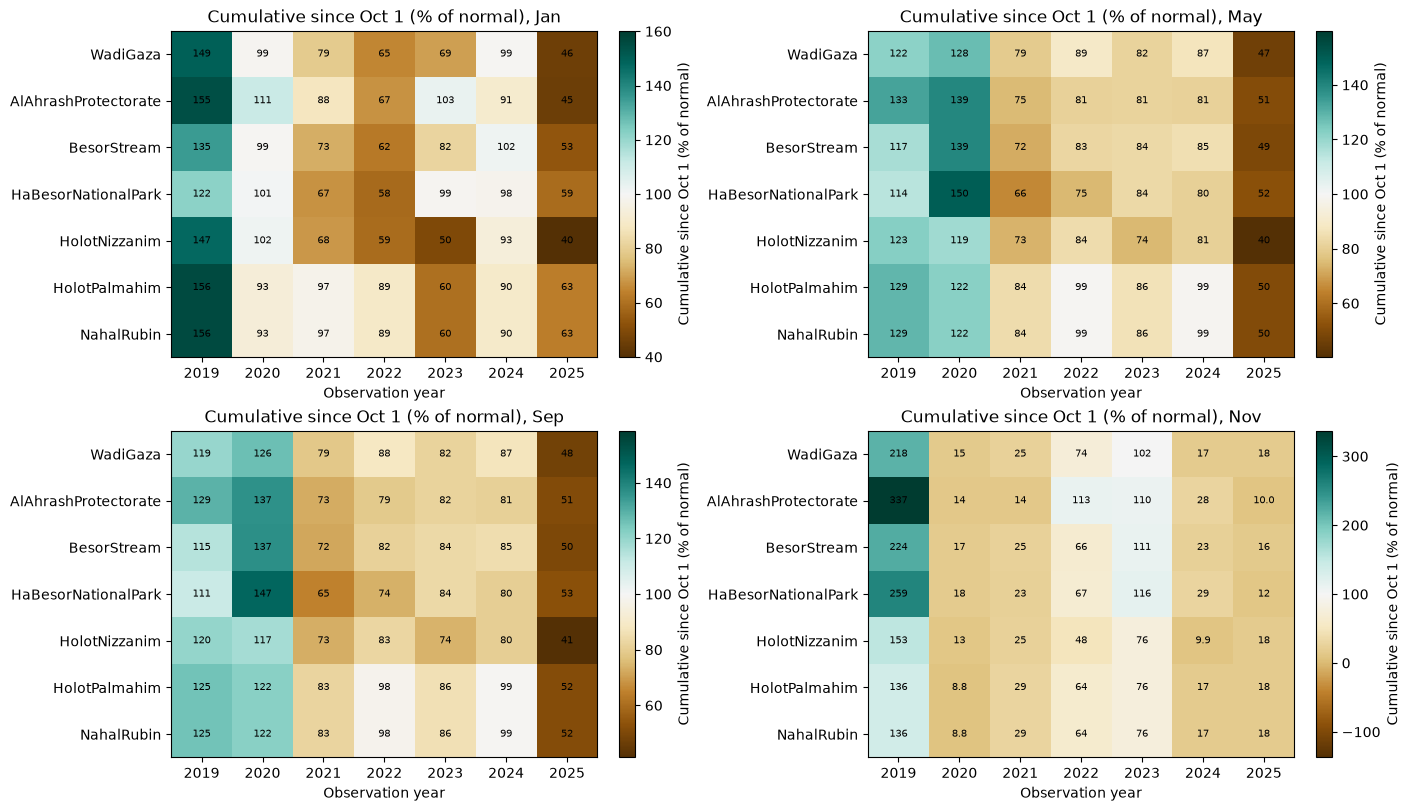

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for ax, month in zip(axes.flat, config.study_months):
    plot_summary_heatmap(summary, "cum_since_oct1_precip_pct_normal", month, ax=ax,
                         flag="cum_since_oct1_precip_near_zero_normal",
                         label="Cumulative since Oct 1 (% of normal)", sites=SITE_ORDER)
save_figure(fig, PLOT_DIR / "cumulative_pct_normal_heatmaps.png")
plt.show()

## Temperature anomaly by site

Monthly anomalies from the 1991–2020 normal for each study month. Solid lines use the 24-hour mean and dashed lines the (max + min) / 2 midrange.

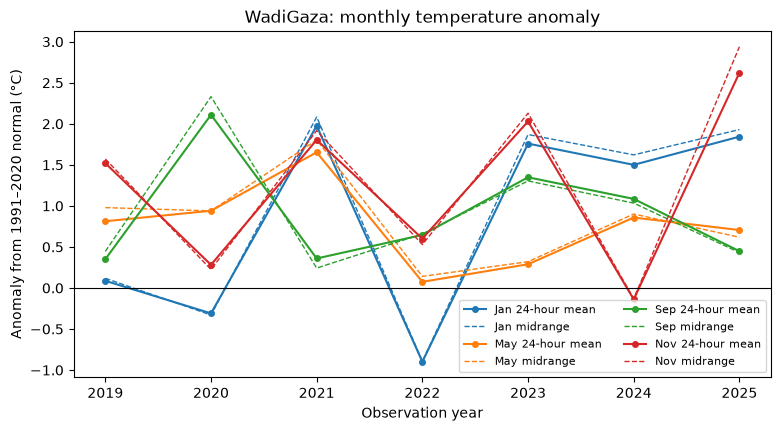

In [10]:
fig, ax = plot_temperature_anomalies(summary, FOCUS_SITE)
save_figure(fig, PLOT_DIR / f"{FOCUS_SITE}_temperature_anomaly.png")
plt.show()

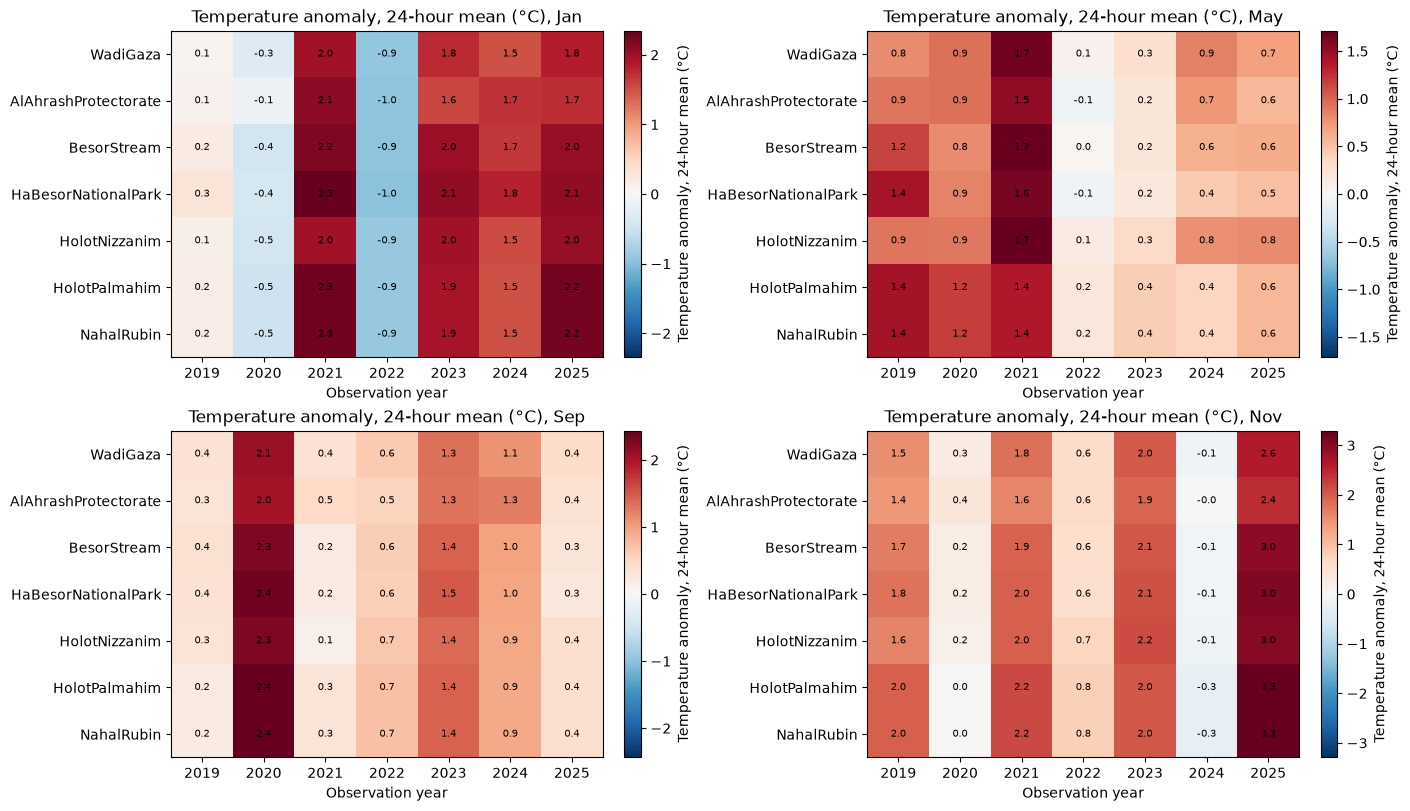

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for ax, month in zip(axes.flat, config.study_months):
    plot_summary_heatmap(summary, "t2m_mean_24h_anom_c", month, ax=ax,
                         label="Temperature anomaly, 24-hour mean (\N{DEGREE SIGN}C)", sites=SITE_ORDER)
save_figure(fig, PLOT_DIR / "temperature_anomaly_heatmaps.png")
plt.show()

## Monthly climatology with observed 2019–2025 totals

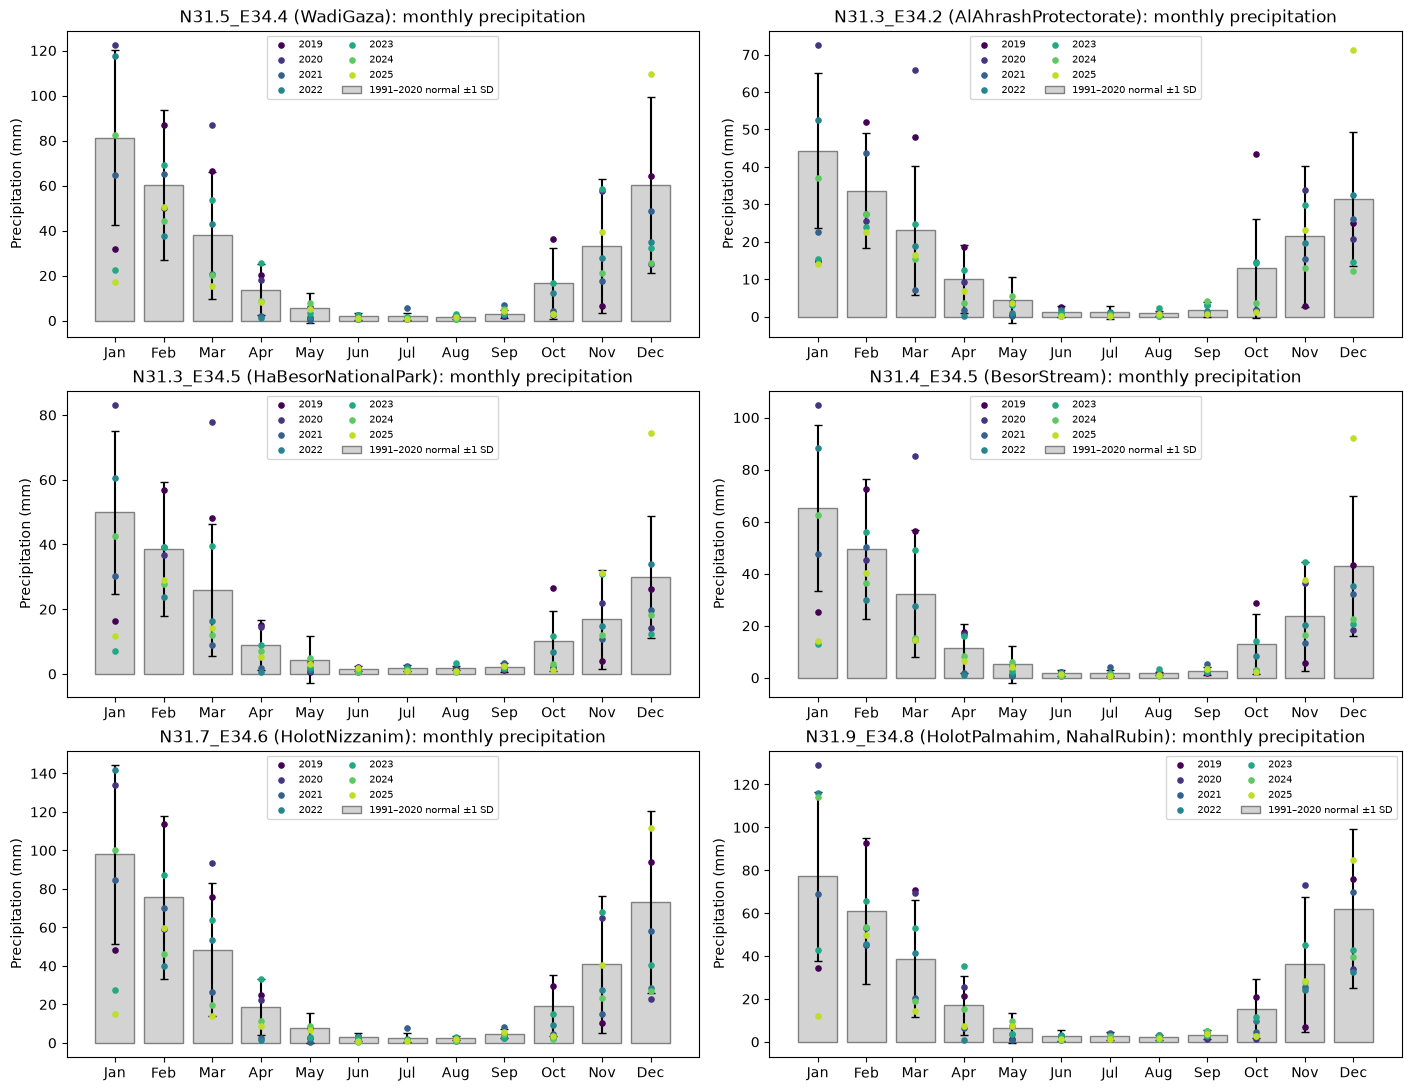

In [12]:
cell_order = [FOCUS_CELL] + sorted(set(site_cells["cell_id"]) - {FOCUS_CELL})
nrows = (len(cell_order) + 1) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(14, 3.6 * nrows), constrained_layout=True)
for ax, cell in zip(axes.flat, cell_order):
    plot_climatology(normals, daily, cell, config.study_period_years, ax=ax)
    users = ", ".join(site_cells.loc[site_cells["cell_id"] == cell, "site"])
    ax.set_title(f"{cell} ({users}): monthly precipitation")
for ax in list(axes.flat)[len(cell_order):]:
    ax.set_visible(False)
save_figure(fig, PLOT_DIR / "monthly_climatology.png")
plt.show()

## Cumulative precipitation since October 1

Seasons 2017/18 to 2024/25 for the Wadi Gaza cell against the 1991–2020 envelope (seasons 1990/91 to 2019/20).

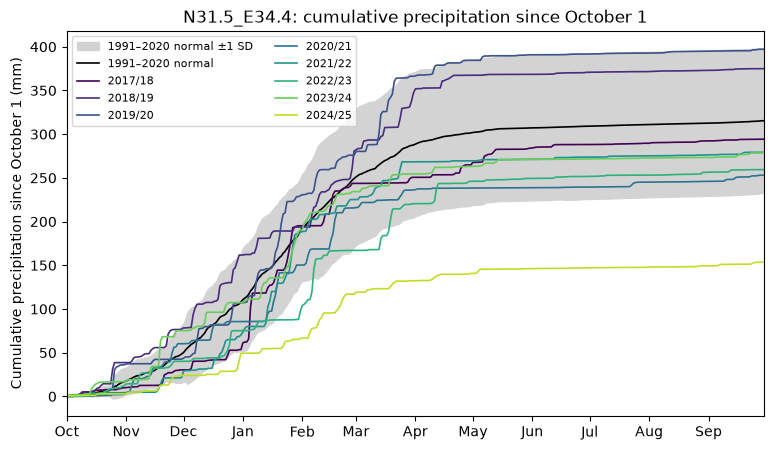

In [13]:
fig, ax = plot_cumulative_seasons(
    daily, FOCUS_CELL,
    end_years=range(config.study_years[0] - 1, config.study_years[1] + 1),
    reference_end_years=config.reference_years,
)
save_figure(fig, PLOT_DIR / f"{FOCUS_SITE}_cumulative_since_oct1.png")
plt.show()

## Wadi Gaza cell-choice sensitivity

The Wadi Gaza centroid lies about 300 m inside the southern edge of its cell. This compares the assigned cell with the cell to the south, using the regional summary.

,cell_id,measure,mean,sd
614,N31.4_E34.4,wet_season_precip_mm,236.7,63.0
819,N31.5_E34.4,wet_season_precip_mm,301.5,83.1


Differences (N31.5_E34.4 minus N31.4_E34.4) across the 28 study months:


,precip_anom_mm,wet_season_precip_pct_normal,cum_since_oct1_precip_pct_normal,t2m_mean_24h_anom_c
mean,-0.40,-0.10,-2.03,-0.02
min,-15.86,-7.44,-33.14,-0.20
max,14.22,5.11,5.24,0.15


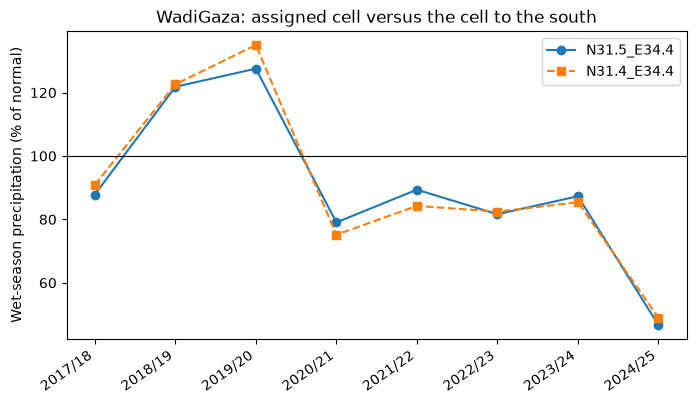

In [14]:
ALTERNATE_CELL = "N31.4_E34.4"
compare_columns = ["precip_anom_mm", "wet_season_precip_pct_normal", "cum_since_oct1_precip_pct_normal",
                   "t2m_mean_24h_anom_c"]
pair = regional.loc[regional["cell_id"].isin([FOCUS_CELL, ALTERNATE_CELL])]
wide = pair.pivot_table(index=["year", "month"], columns="cell_id", values=compare_columns)
differences = pd.DataFrame({
    column: wide[(column, FOCUS_CELL)] - wide[(column, ALTERNATE_CELL)] for column in compare_columns
})
wet_normals = normals.loc[normals["cell_id"].isin([FOCUS_CELL, ALTERNATE_CELL])
                          & (normals["measure"] == "wet_season_precip_mm")]
display(wet_normals[["cell_id", "measure", "mean", "sd"]].round(1))
print(f"Differences ({FOCUS_CELL} minus {ALTERNATE_CELL}) across the 28 study months:")
display(differences.describe().loc[["mean", "min", "max"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for cell, style in ((FOCUS_CELL, "-o"), (ALTERNATE_CELL, "--s")):
    rows = pair.loc[pair["cell_id"] == cell].drop_duplicates("wet_season_label").sort_values("wet_season_label")
    ax.plot(rows["wet_season_label"], rows["wet_season_precip_pct_normal"], style, label=cell)
ax.axhline(100, color="black", linewidth=0.8)
ax.set_ylabel("Wet-season precipitation (% of normal)")
ax.set_title(f"{FOCUS_SITE}: assigned cell versus the cell to the south")
ax.legend()
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save_figure(fig, PLOT_DIR / f"{FOCUS_SITE}_cell_sensitivity.png")
plt.show()

## Temperature method diagnostic

Mean difference between the midrange and 24-hour mean daily temperature by calendar month, for the cells used by sites. Positive values mean the midrange runs warmer.

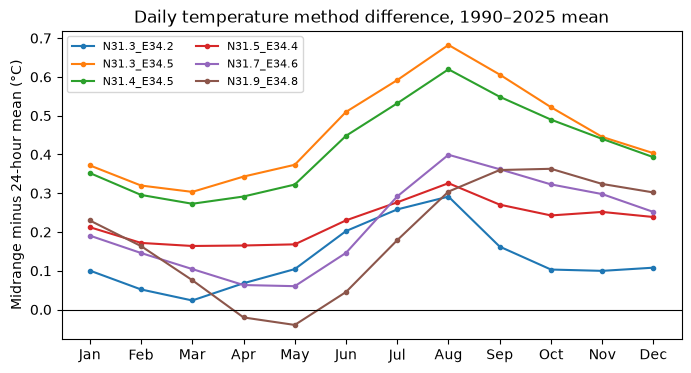

In [15]:
fig, ax = plot_temperature_method_difference(daily.loc[daily["cell_id"].isin(site_cells["cell_id"])])
save_figure(fig, PLOT_DIR / "temperature_method_difference.png")
plt.show()